In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error

In [2]:
df = pd.DataFrame({
    "Height": [160, 165, 170, 175, 180, 185],
    "Weight": [50, 55, 60, 65, 70, 75],
    "Age": [20, 22, 21, 24, 23, 25]
})

df

,Height,Weight,Age
0,160,50,20
1,165,55,22
2,170,60,21
3,175,65,24
4,180,70,23
5,185,75,25


In [5]:
X_train, X_test = train_test_split(
    df, test_size=0.2, random_state=42
)


In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [7]:
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

In [8]:
explained_variance_ratio = pca.explained_variance_ratio_

print(explained_variance_ratio)

[0.92594433 0.07405567]


In [9]:
cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

print(cumulative_variance)

[0.92594433 1.        ]


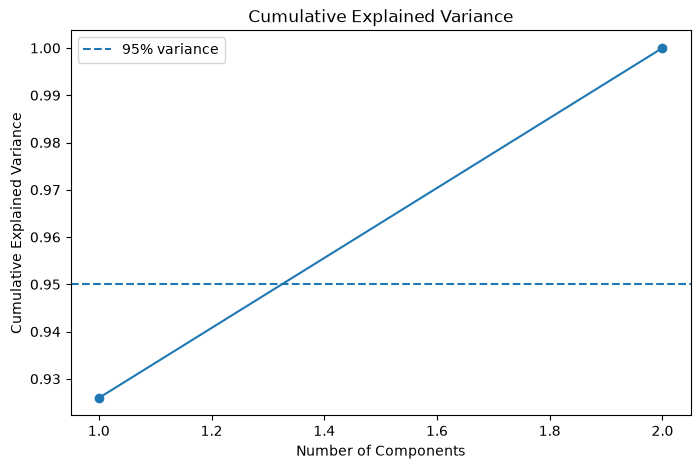

In [11]:
cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    y=0.95,
    linestyle="--",
    label="95% variance"
)

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance")

plt.legend()
plt.show()

In [14]:
# Inverse transform
X_reconstructed = pca.inverse_transform(X_test_pca)

print("Original shape:", X_test_scaled.shape)
print("PCA transformed shape:", X_test_pca.shape)
print("Reconstructed shape:", X_reconstructed.shape)

Original shape: (2, 3)
PCA transformed shape: (2, 2)
Reconstructed shape: (2, 3)


In [15]:
X_reconstructed_original = scaler.inverse_transform(
    X_reconstructed
)

df_reconstructed = pd.DataFrame(
    X_reconstructed_original,
    columns=df.columns
)

df_reconstructed

,Height,Weight,Age
0,160.0,50.0,20.0
1,165.0,55.0,22.0


In [17]:
# Squared reconstruction error
reconstruction_error = np.sum(
    (X_test_scaled - X_reconstructed) ** 2
)

print("Reconstruction Error:", reconstruction_error)

Reconstruction Error: 2.2186712959340957e-30


In [18]:
# Retained variance
retained_variance = pca.explained_variance_ratio_.sum()

# Information loss
information_loss = 1 - retained_variance

print("Retained Variance:", retained_variance)
print("Information Loss:", information_loss)
print("Information Loss (%):", information_loss * 100)

Retained Variance: 1.0
Information Loss: 0.0
Information Loss (%): 0.0
